# Learned information objectives and contrastive saturation

These models are genuinely trained with separate train/validation/test draws. Population variational bounds do not certify a finite empirical estimate; batch saturation, critic misspecification and variance are measured outcomes.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
import torch
from information_lab.neural import load, evaluate

torch.set_num_threads(1)
record, path = query("neural", method="mine_dv", dimension=4, correlation=0.7)[0]
model, metadata = load(path / "model.npz", device="cpu")
data = arrays(path)
result = evaluate(
    model,
    torch.tensor(data["test_x"], dtype=torch.float32),
    torch.tensor(data["test_y"], dtype=torch.float32),
    record["config"]["batch_size"],
)
print(
    "Portable CPU inference:",
    result["estimate_bits"],
    "recorded GPU estimate:",
    record["metrics"]["estimate_bits"],
)
assert np.isclose(result["estimate_bits"], record["metrics"]["estimate_bits"], atol=3e-5)

Portable CPU inference: 1.894396466490475 recorded GPU estimate: 1.894396466490475


**Recorded configuration**

{
  "family": "neural",
  "id": "mine_dv_d4_r70",
  "method": "mine_dv",
  "dimension": 4,
  "correlation": 0.7,
  "train_size": 8192,
  "validation_size": 4096,
  "test_size": 4096,
  "batch_size": 256,
  "steps": 1500,
  "learning_rate": 0.001,
  "validate_every": 100,
  "width": 128
}
{
  "estimate_bits": 1.894396466490475,
  "true_bits": 1.9428616956064577,
  "validation_bits": 2.0539633458221958,
  "selected_step": 1300,
  "fit_seconds": 4.991219215095043,
  "device": "cuda:0",
  "batch_ceiling_bits": null,
  "scope": "MINE-style bounded DV critic with EMA gradient normalization, or separable InfoNCE critic. Independent train/validation/test draws; validation-only checkpoint selection. Finite empirical estimates are not certified bounds and are not clipped to the known truth."
}


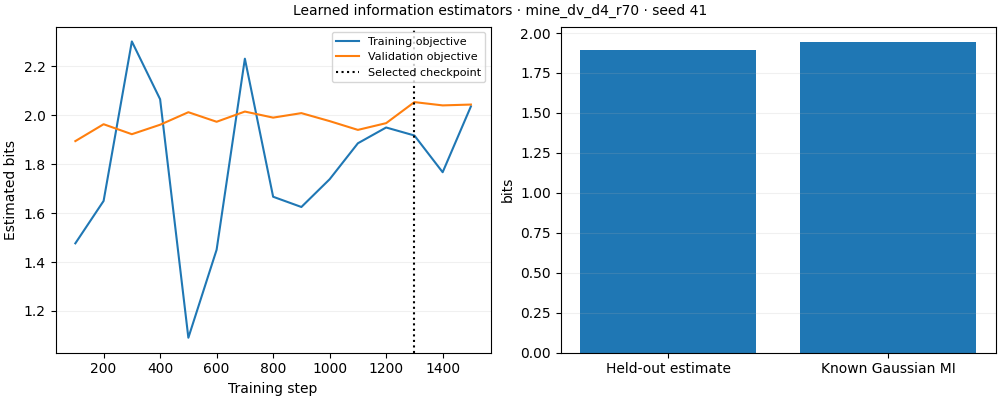

Checkpoint selected on validation: 1300


In [3]:
measured(record)
preview(record)
print("Checkpoint selected on validation:", metadata["selected_step"])

An InfoNCE batch of 256 has ceiling eight bits. At dimension 16 and correlation 0.95, Gaussian MI is approximately 26.87 bits. A nearly perfect eight-bit objective therefore remains a severely underestimated MI value.

In [4]:
for seed in [41, 42, 43]:
    record, path = query("neural", method="infonce", dimension=16, correlation=0.95, seed=seed)[0]
    print(seed, record["metrics"])
assert record["metrics"]["estimate_bits"] <= np.log2(record["config"]["batch_size"]) + 1e-7

41 {'estimate_bits': 7.995539092988941, 'true_bits': 26.867631767299805, 'validation_bits': 7.997189954454573, 'selected_step': 1500, 'fit_seconds': 5.410567189566791, 'device': 'cuda:0', 'batch_ceiling_bits': 8.0, 'scope': 'MINE-style bounded DV critic with EMA gradient normalization, or separable InfoNCE critic. Independent train/validation/test draws; validation-only checkpoint selection. Finite empirical estimates are not certified bounds and are not clipped to the known truth.'}
42 {'estimate_bits': 7.996985166113058, 'true_bits': 26.867631767299805, 'validation_bits': 7.997512679898916, 'selected_step': 1500, 'fit_seconds': 4.737576828338206, 'device': 'cuda:1', 'batch_ceiling_bits': 8.0, 'scope': 'MINE-style bounded DV critic with EMA gradient normalization, or separable InfoNCE critic. Independent train/validation/test draws; validation-only checkpoint selection. Finite empirical estimates are not certified bounds and are not clipped to the known truth.'}
43 {'estimate_bits': 7

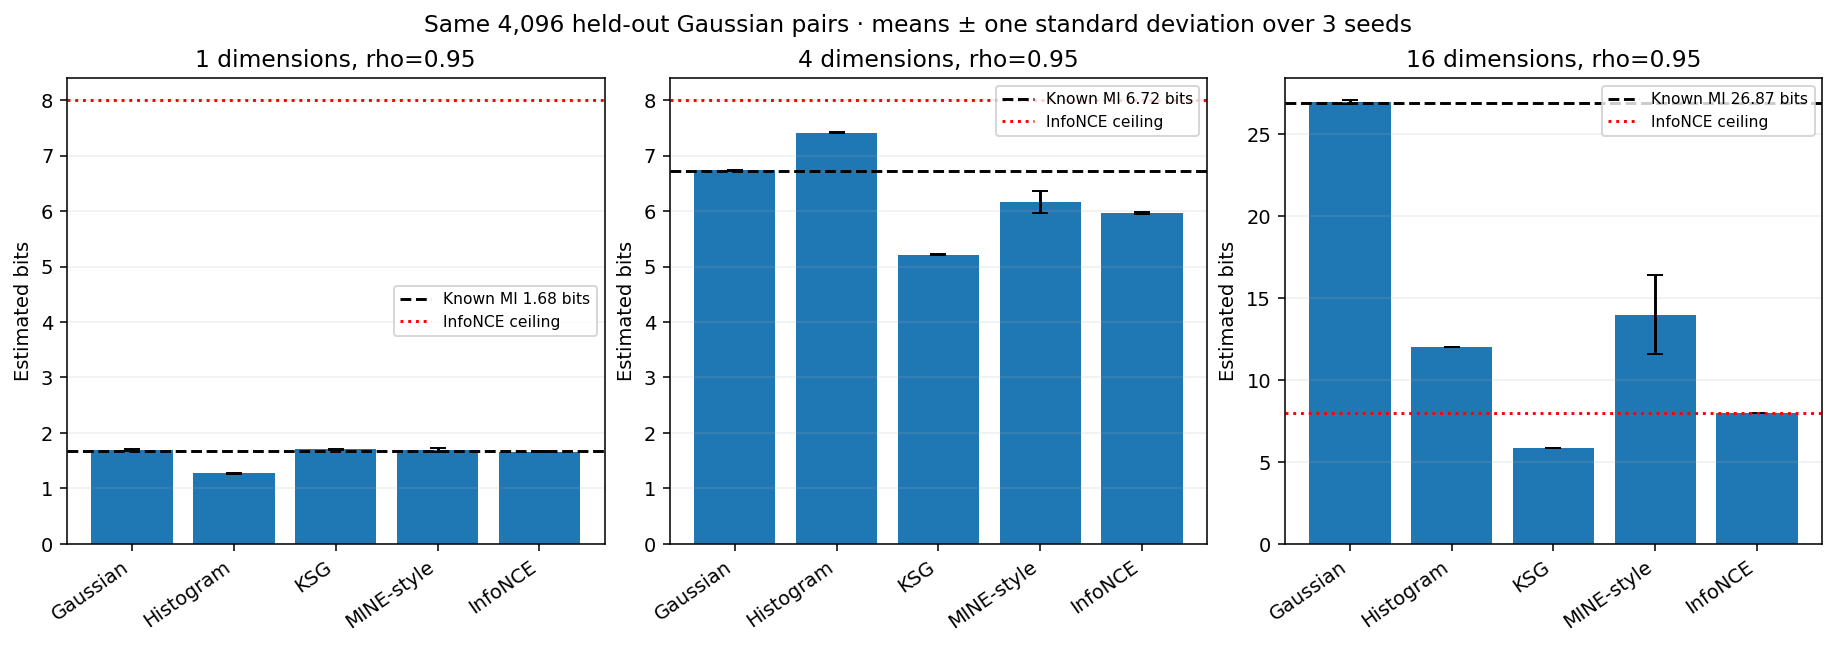

In [5]:
display(Image(filename=str(ROOT / "assets/previews/mi_comparison.png")))

NPZ states use `allow_pickle=False`; model inference does not deserialize arbitrary Python objects. The audit reloads every saved critic on CPU and compares its held-out objective. The correct Gaussian-family baseline is intentionally included, rather than assuming neural estimators must win.